# 1. Đọc dữ liệu đã qua tiền xử lý E13


In [1]:
from pathlib import Path
import inspect
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler,
    OneHotEncoder
)
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# ========================================
# 1. CẤU HÌNH THỰC NGHIỆM E13
# ========================================

EXPERIMENT_ID = "E13"
COMPARE_ID = "E12"

TARGET = "Attack_type"
RANDOM_STATE = 42
N_SPLITS = 3

# ========================================
# 2. TÌM THƯ MỤC GỐC
# ========================================

CURRENT = Path.cwd().resolve()

ROOT = next(
    (
        p for p in [CURRENT, *CURRENT.parents]
        if (p / "project").is_dir()
        and (p / "result").is_dir()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục IoT_final. "
        "Hãy mở VS Code tại thư mục dự án."
    )

# ========================================
# 3. ĐƯỜNG DẪN TRAIN / VALIDATION
# ========================================

DATA_DIR = (
    ROOT / "result"
    / "preprocessing"
    / "E13_MLP_SignedLog2_Processing"
    / "data"
)

TRAIN_PATH = DATA_DIR / "train.csv.gz"
VALID_PATH = DATA_DIR / "validation.csv.gz"

# ========================================
# 4. THƯ MỤC KẾT QUẢ E13
# ========================================

RESULT_DIR = (
    ROOT / "result"
    / "exps"
    / "E13_MLP_SignedLog2"
)

# Chỉ có một folder kết quả
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ========================================
# 5. ĐỌC DỮ LIỆU
# ========================================

if not TRAIN_PATH.is_file():
    raise FileNotFoundError(TRAIN_PATH)

if not VALID_PATH.is_file():
    raise FileNotFoundError(VALID_PATH)

train_df = pd.read_csv(TRAIN_PATH)
valid_df = pd.read_csv(VALID_PATH)

print("=== THỰC NGHIỆM E13 ===")
print("MLP + Signed-log + StandardScaler")
print("Hidden layers: (128, 64)")

print("\n=== KÍCH THƯỚC DỮ LIỆU ===")
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)

print("\n=== THƯ MỤC KẾT QUẢ ===")
print(RESULT_DIR)

print("\n=== DỮ LIỆU TRAIN ===")
display(train_df.head())

=== THỰC NGHIỆM E13 ===
MLP + Signed-log + StandardScaler
Hidden layers: (128, 64)

=== KÍCH THƯỚC DỮ LIỆU ===
Train: (82536, 83)
Validation: (17686, 83)

=== THƯ MỤC KẾT QUẢ ===
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\exps\E13_MLP_SignedLog2

=== DỮ LIỆU TRAIN ===


,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,11.069416,10.747917,udp,-,0.000000,0.693147,0.000000,0.693147,0.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,NMAP_UDP_SCAN
1,9.913933,3.091042,tcp,-,0.000005,0.693147,0.693147,0.693147,0.0,12.204721,...,0.0,0.0,0.0,0.0,0.0,0.0,4.174387,0.0,4.174387,DOS_SYN_Hping
2,8.214736,3.091042,tcp,-,0.000005,0.693147,0.693147,0.693147,0.0,12.204721,...,0.0,0.0,0.0,0.0,0.0,0.0,4.174387,0.0,4.174387,DOS_SYN_Hping
3,10.593530,3.091042,tcp,-,0.000002,0.693147,0.693147,0.693147,0.0,13.052016,...,0.0,0.0,0.0,0.0,0.0,0.0,4.174387,0.0,4.174387,DOS_SYN_Hping
4,9.145268,3.091042,tcp,-,0.000004,0.693147,0.693147,0.693147,0.0,12.416029,...,0.0,0.0,0.0,0.0,0.0,0.0,4.174387,0.0,4.174387,DOS_SYN_Hping


# 2. Xây dựng Pipeline Signed-Log + StandardScaler + MLP (128,64)

In [2]:
# ========================================
# 1. TÁCH ĐẶC TRƯNG VÀ NHÃN
# ========================================

DROP_COLS = [
    TARGET,
    "Unnamed: 0",
    "group_id"
]

CATEGORICAL_FEATURES = [
    "proto",
    "service"
]

if (
    TARGET not in train_df.columns
    or TARGET not in valid_df.columns
):
    raise ValueError(
        f"Thiếu cột nhãn {TARGET}"
    )

if (
    train_df[TARGET].isna().any()
    or valid_df[TARGET].isna().any()
):
    raise ValueError("Nhãn chứa giá trị thiếu")

X = train_df.drop(
    columns=DROP_COLS,
    errors="ignore"
).copy()

y = train_df[TARGET].astype(str).copy()

X_valid = valid_df.drop(
    columns=DROP_COLS,
    errors="ignore"
).copy()

y_valid = valid_df[TARGET].astype(str).copy()

# Đồng bộ thứ tự đặc trưng
if set(X.columns) != set(X_valid.columns):
    raise ValueError(
        "Train và Validation không có cùng đặc trưng"
    )

X_valid = X_valid[X.columns]

# ========================================
# 2. XÁC ĐỊNH CÁC LOẠI ĐẶC TRƯNG
# ========================================

missing_categorical = [
    col for col in CATEGORICAL_FEATURES
    if col not in X.columns
]

if missing_categorical:
    raise ValueError(
        f"Thiếu cột categorical: {missing_categorical}"
    )

NUMERIC_FEATURES = X.select_dtypes(
    include=np.number
).columns.tolist()

unknown_features = sorted(
    set(X.columns)
    - set(NUMERIC_FEATURES)
    - set(CATEGORICAL_FEATURES)
)

if unknown_features:
    raise ValueError(
        f"Cột chưa được xử lý: {unknown_features}"
    )

# ========================================
# 3. KIỂM TRA DỮ LIỆU
# ========================================

if X.isna().any().any() or X_valid.isna().any().any():
    raise ValueError(
        "Dữ liệu còn NaN, cần kiểm tra các tập đã chia sẵn"
    )

if not np.isfinite(
    X[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError("Train có giá trị vô hạn")

if not np.isfinite(
    X_valid[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError("Validation có giá trị vô hạn")

LABELS = sorted(y.unique().tolist())

if not set(y_valid.unique()).issubset(set(LABELS)):
    raise ValueError(
        "Validation chứa nhãn không có trong Train"
    )

if y.value_counts().min() < N_SPLITS:
    raise ValueError(
        "Có lớp không đủ 3 mẫu cho 3-fold CV"
    )

# ========================================
# 4. HÀM SIGNED-LOG
# ========================================

def signed_log(values):
    """
    Signed-log:
    sign(x) * log(1 + abs(x))
    """

    values = np.asarray(
        values,
        dtype=np.float64
    )

    return (
        np.sign(values)
        * np.log1p(np.abs(values))
    )


# ========================================
# 5. HÀM TẠO PIPELINE E13
# ========================================

def make_e13_pipeline():

    ohe_args = {
        "handle_unknown": "ignore"
    }

    # Tương thích các phiên bản sklearn
    if "sparse_output" in inspect.signature(
        OneHotEncoder
    ).parameters:
        ohe_args["sparse_output"] = False
    else:
        ohe_args["sparse"] = False

    # Signed-log đã được thực hiện trong notebook Processing.
    # StandardScaler được fit riêng theo từng fold CV.
    numeric_pipeline = Pipeline([
        ("scaler", StandardScaler())
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_pipeline,
                NUMERIC_FEATURES
            ),
            (
                "categorical",
                OneHotEncoder(**ohe_args),
                CATEGORICAL_FEATURES
            )
        ],
        remainder="drop",
        sparse_threshold=0
    )

    # MLP E13: 2 lớp ẩn (128, 64)
    mlp = MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        learning_rate_init=0.001,
        batch_size=512,
        max_iter=60,
        n_iter_no_change=8,
        early_stopping=False,
        random_state=RANDOM_STATE,
        verbose=False
    )

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", mlp)
    ])


# ========================================
# 6. HÀM ĐÁNH GIÁ
# ========================================

METRICS = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "macro_precision",
    "macro_recall"
]


def evaluate(y_true, y_pred):

    return {
        "accuracy": accuracy_score(
            y_true, y_pred
        ),

        "macro_f1": f1_score(
            y_true, y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            y_true, y_pred,
            labels=LABELS,
            average="weighted",
            zero_division=0
        ),

        "macro_precision": precision_score(
            y_true, y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            y_true, y_pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        )
    }


# ========================================
# 7. KIỂM TRA CẤU HÌNH
# ========================================

print("=== CẤU HÌNH E13 ===")

print("Train:", len(X))
print("Validation:", len(X_valid))
print("Số lớp:", len(LABELS))
print("Số đặc trưng số:", len(NUMERIC_FEATURES))
print("Categorical:", CATEGORICAL_FEATURES)

print("\n=== PIPELINE E13 ===")
print(make_e13_pipeline())

print("\n=== KIỂM TRA SIGNED-LOG ===")

sample_values = np.array(
    [-100, -10, -1, 0, 1, 10, 100],
    dtype=float
)

display(pd.DataFrame({
    "original": sample_values,
    "signed_log": signed_log(sample_values)
}))

=== CẤU HÌNH E13 ===
Train: 82536
Validation: 17686
Số lớp: 12
Số đặc trưng số: 80
Categorical: ['proto', 'service']

=== PIPELINE E13 ===
Pipeline(steps=[('preprocess',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['id.orig_p', 'id.resp_p',
                                                   'flow_duration',
                                                   'fwd_pkts_tot',
                                                   'bwd_pkts_tot',
                                                   'fwd_data_pkts_tot',
                                                   'bwd_data_pkts_tot',
                                                   'fwd_pkts_per_sec',
                                                   'bwd

,original,signed_log
0,-100.0,-4.615121
1,-10.0,-2.397895
2,-1.0,-0.693147
3,0.0,0.000000
4,1.0,0.693147
5,10.0,2.397895
6,100.0,4.615121


### Tiền xử lý MLP E13

- Notebook Processing áp dụng Signed-log: `sign(x) × ln(1 + |x|)` cho đặc trưng số.
- Pipeline thực nghiệm tiếp tục dùng StandardScaler và OneHotEncoder.
- Các bộ biến đổi được fit bên trong từng fold Cross-Validation.


# 3. Huấn luyện E13 bằng 3-ford Cross-Validation

In [3]:
# ========================================
# 3-FOLD CROSS-VALIDATION E13
# ========================================

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_rows = []
per_class_rows = []
loss_curves = {}

for fold, (fit_idx, cv_idx) in enumerate(
    cv.split(X, y),
    start=1
):

    print("\n" + "=" * 55)
    print(f"E13 - FOLD {fold}/{N_SPLITS}")
    print("=" * 55)

    # Dữ liệu Train trong fold
    X_fit = X.iloc[fit_idx]
    y_fit = y.iloc[fit_idx]

    # Dữ liệu kiểm định trong fold
    X_cv = X.iloc[cv_idx]
    y_cv = y.iloc[cv_idx]

    # Mỗi fold tạo Pipeline mới
    fold_pipeline = make_e13_pipeline()

    start_time = time.perf_counter()

    # Huấn luyện
    fold_pipeline.fit(X_fit, y_fit)

    elapsed = time.perf_counter() - start_time

    # Dự đoán
    pred_cv = fold_pipeline.predict(X_cv)
    pred_train = fold_pipeline.predict(X_fit)

    # Tính 5 chỉ số
    cv_scores = evaluate(y_cv, pred_cv)
    train_scores = evaluate(y_fit, pred_train)

    trained_mlp = fold_pipeline.named_steps["model"]

    # Lưu Training Loss
    loss_curves[fold] = list(
        trained_mlp.loss_curve_
    )

    # Lưu kết quả fold
    fold_rows.append({
        "fold": fold,
        "n_train": len(X_fit),
        "n_cv": len(X_cv),
        "epochs": int(trained_mlp.n_iter_),
        "training_time_sec": float(elapsed),
        "final_train_loss": float(trained_mlp.loss_),

        **cv_scores,

        **{
            f"train_{m}": train_scores[m]
            for m in METRICS
        }
    })

    # Tính chỉ số theo từng lớp
    p, r, f, support = (
        precision_recall_fscore_support(
            y_cv,
            pred_cv,
            labels=LABELS,
            zero_division=0
        )
    )

    for label, precision, recall, f1_value, n in zip(
        LABELS, p, r, f, support
    ):

        per_class_rows.append({
            "fold": fold,
            "class": label,
            "precision": float(precision),
            "recall": float(recall),
            "f1": float(f1_value),
            "support": int(n)
        })

    print("Số mẫu Train:", len(X_fit))
    print("Số mẫu CV:", len(X_cv))
    print("Số epoch:", trained_mlp.n_iter_)
    print(f"Thời gian: {elapsed:.2f} giây")

    print("\n=== 5 CHỈ SỐ FOLD ===")

    for metric in METRICS:
        print(
            f"{metric:18s}: {cv_scores[metric]:.6f}"
        )

# ========================================
# TỔNG HỢP KẾT QUẢ
# ========================================

cv_results = pd.DataFrame(fold_rows)
cv_per_class = pd.DataFrame(per_class_rows)

cv_summary = pd.DataFrame({
    "metric": METRICS,

    "mean": [
        float(cv_results[m].mean())
        for m in METRICS
    ],

    "std": [
        float(cv_results[m].std(ddof=1))
        for m in METRICS
    ]
})

cv_per_class_summary = (
    cv_per_class
    .groupby("class", as_index=False)
    .agg(
        precision_mean=("precision", "mean"),
        recall_mean=("recall", "mean"),
        f1_mean=("f1", "mean"),
        support_total=("support", "sum")
    )
    .sort_values("f1_mean")
)

print("\n=== KẾT QUẢ 3 FOLD ===")

display(
    cv_results[
        [
            "fold",
            *METRICS,
            "epochs",
            "training_time_sec"
        ]
    ].round(6)
)

print("\n=== TRUNG BÌNH 3 FOLD ===")
display(cv_summary.round(6))

print("\n=== 5 LỚP CÓ F1 THẤP NHẤT ===")

display(
    cv_per_class_summary
    .head(5)
    .round(6)
)

# ========================================
# LƯU KẾT QUẢ VÀO FOLDER E13
# ========================================

cv_results.to_csv(
    RESULT_DIR / "E13_cv_folds.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_summary.to_csv(
    RESULT_DIR / "E13_cv_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_per_class.to_csv(
    RESULT_DIR / "E13_cv_per_class.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_per_class_summary.to_csv(
    RESULT_DIR / "E13_cv_per_class_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu kết quả 3-fold CV.")


E13 - FOLD 1/3
Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 57
Thời gian: 17.57 giây

=== 5 CHỈ SỐ FOLD ===
accuracy          : 0.996329
macro_f1          : 0.954224
weighted_f1       : 0.996276
macro_precision   : 0.988982
macro_recall      : 0.927977

E13 - FOLD 2/3
Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 55
Thời gian: 18.73 giây

=== 5 CHỈ SỐ FOLD ===
accuracy          : 0.995566
macro_f1          : 0.930774
weighted_f1       : 0.995506
macro_precision   : 0.963820
macro_recall      : 0.913759

E13 - FOLD 3/3
Số mẫu Train: 55024
Số mẫu CV: 27512
Số epoch: 59
Thời gian: 19.49 giây

=== 5 CHỈ SỐ FOLD ===
accuracy          : 0.996147
macro_f1          : 0.963000
weighted_f1       : 0.996118
macro_precision   : 0.966807
macro_recall      : 0.961287

=== KẾT QUẢ 3 FOLD ===


,fold,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,epochs,training_time_sec
0,1,0.996329,0.954224,0.996276,0.988982,0.927977,57,17.565324
1,2,0.995566,0.930774,0.995506,0.963820,0.913759,55,18.732631
2,3,0.996147,0.963000,0.996118,0.966807,0.961287,59,19.494096



=== TRUNG BÌNH 3 FOLD ===


,metric,mean,std
0,accuracy,0.996014,0.000399
1,macro_f1,0.949333,0.016661
2,weighted_f1,0.995967,0.000407
3,macro_precision,0.973203,0.013747
4,macro_recall,0.934341,0.024395



=== 5 LỚP CÓ F1 THẤP NHẤT ===


,class,precision_mean,recall_mean,f1_mean,support_total
4,Metasploit_Brute_Force_SSH,0.925926,0.754630,0.810458,25
5,NMAP_FIN_SCAN,0.916667,0.841270,0.866667,20
11,Wipro_bulb,0.930540,0.856209,0.890753,153
1,DDOS_Slowloris,0.987148,0.815032,0.892851,373
8,NMAP_UDP_SCAN,0.963790,0.986717,0.975118,1807



Đã lưu kết quả 3-fold CV.


### Huấn luyện E13 bằng 3-fold Cross-Validation

**Mục tiêu:**

Đánh giá mô hình MLP (128, 64) sử dụng
Signed-log và StandardScaler bằng phương pháp
3-fold Cross-Validation.

**Quy trình:**
- Sử dụng StratifiedKFold với 3 fold.
- Mỗi fold khởi tạo một Pipeline mới.
- Huấn luyện trên 2 fold.


# 4. Huấn luyện toàn bộ Train và đánh giá Validation

In [4]:
# ========================================
# 1. HUẤN LUYỆN TOÀN BỘ TRAIN
# ========================================

final_model = make_e13_pipeline()

start_time = time.perf_counter()

final_model.fit(X, y)

full_train_time = (
    time.perf_counter() - start_time
)

# Dự đoán
pred_train = final_model.predict(X)
pred_valid = final_model.predict(X_valid)

# Tính chỉ số
train_scores = evaluate(y, pred_train)
valid_scores = evaluate(y_valid, pred_valid)

final_mlp = final_model.named_steps["model"]

print("=== E13 - FULL TRAIN ===")
print("Số mẫu Train:", len(X))
print("Số epoch:", final_mlp.n_iter_)
print(f"Thời gian: {full_train_time:.2f} giây")
print(f"Training Loss: {final_mlp.loss_:.6f}")

# ========================================
# 2. BẢNG TRAIN / VALIDATION
# ========================================

validation_metrics = pd.DataFrame({
    "metric": METRICS,

    "train": [
        train_scores[m]
        for m in METRICS
    ],

    "validation": [
        valid_scores[m]
        for m in METRICS
    ]
})

validation_metrics["train_valid_gap"] = (
    validation_metrics["train"]
    - validation_metrics["validation"]
)

print("\n=== TRAIN / VALIDATION ===")

display(validation_metrics.round(6))

# ========================================
# 3. ĐÁNH GIÁ THEO TỪNG LỚP
# ========================================

p, r, f, support = (
    precision_recall_fscore_support(
        y_valid,
        pred_valid,
        labels=LABELS,
        zero_division=0
    )
)

validation_per_class = pd.DataFrame({
    "class": LABELS,
    "precision": p,
    "recall": r,
    "f1": f,
    "support": support
})

print("\n=== KẾT QUẢ THEO TỪNG LỚP ===")

display(
    validation_per_class
    .sort_values("f1")
    .round(6)
)

# ========================================
# 4. CONFUSION MATRIX
# ========================================

cm = confusion_matrix(
    y_valid,
    pred_valid,
    labels=LABELS
)

cm_df = pd.DataFrame(
    cm,
    index=LABELS,
    columns=LABELS
)

# ========================================
# 5. TỔNG HỢP CV VÀ VALIDATION CỦA E13
# ========================================

cv_vs_validation = (
    cv_summary[
        ["metric", "mean", "std"]
    ]
    .merge(
        validation_metrics[
            ["metric", "validation"]
        ],
        on="metric"
    )
)

cv_vs_validation["validation_minus_cv_mean"] = (
    cv_vs_validation["validation"]
    - cv_vs_validation["mean"]
)

print("\n=== CV / VALIDATION E13 ===")

display(cv_vs_validation.round(6))

# ========================================
# 6. LƯU KẾT QUẢ
# ========================================

validation_metrics.to_csv(
    RESULT_DIR / "E13_validation_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

validation_per_class.to_csv(
    RESULT_DIR / "E13_validation_per_class.csv",
    index=False,
    encoding="utf-8-sig"
)

cm_df.to_csv(
    RESULT_DIR / "E13_validation_confusion_matrix.csv",
    encoding="utf-8-sig"
)

cv_vs_validation.to_csv(
    RESULT_DIR / "E13_cv_vs_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu kết quả Validation.")

d:\Programdata2026\Anaconda3\envs\sgu_ml\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


=== E13 - FULL TRAIN ===
Số mẫu Train: 82536
Số epoch: 60
Thời gian: 29.06 giây
Training Loss: 0.006498

=== TRAIN / VALIDATION ===


,metric,train,validation,train_valid_gap
0,accuracy,0.997262,0.996494,0.000767
1,macro_f1,0.964815,0.969411,-0.004595
2,weighted_f1,0.997222,0.996467,0.000755
3,macro_precision,0.992093,0.990887,0.001206
4,macro_recall,0.942770,0.952315,-0.009546



=== KẾT QUẢ THEO TỪNG LỚP ===


,class,precision,recall,f1,support
5,NMAP_FIN_SCAN,1.000000,0.750000,0.857143,4
1,DDOS_Slowloris,1.000000,0.850000,0.918919,80
11,Wipro_bulb,0.966667,0.878788,0.920635,33
8,NMAP_UDP_SCAN,0.964646,0.987080,0.975734,387
0,ARP_poisioning,0.971674,0.990376,0.980936,1143
10,Thing_Speak,0.987654,0.976460,0.982025,1147
9,NMAP_XMAS_TREE_SCAN,1.000000,0.996689,0.998342,302
3,MQTT_Publish,1.000000,0.998390,0.999194,621
7,NMAP_TCP_scan,1.000000,1.000000,1.000000,151
6,NMAP_OS_DETECTION,1.000000,1.000000,1.000000,300



=== CV / VALIDATION E13 ===


,metric,mean,std,validation,validation_minus_cv_mean
0,accuracy,0.996014,0.000399,0.996494,0.000481
1,macro_f1,0.949333,0.016661,0.969411,0.020078
2,weighted_f1,0.995967,0.000407,0.996467,0.000501
3,macro_precision,0.973203,0.013747,0.990887,0.017684
4,macro_recall,0.934341,0.024395,0.952315,0.017974



Đã lưu kết quả Validation.


### Huấn luyện toàn bộ Train và đánh giá Validation

**Mục tiêu:**

Đánh giá khả năng phân loại của mạng MLP
hai lớp ẩn (128, 64) sau khi dữ liệu được
xử lý bằng Signed-log và StandardScaler.

**Quy trình:**
- Khởi tạo một Pipeline E13 mới.
- Huấn luyện trên toàn bộ tập Train.
- Dự đoán trên tập Validation.
- Tính đầy đủ 5 chỉ số đánh giá.
- Đánh giá Precision, Recall và F1 theo từng lớp.

# 5. Vẽ biểu đồ kết quả 

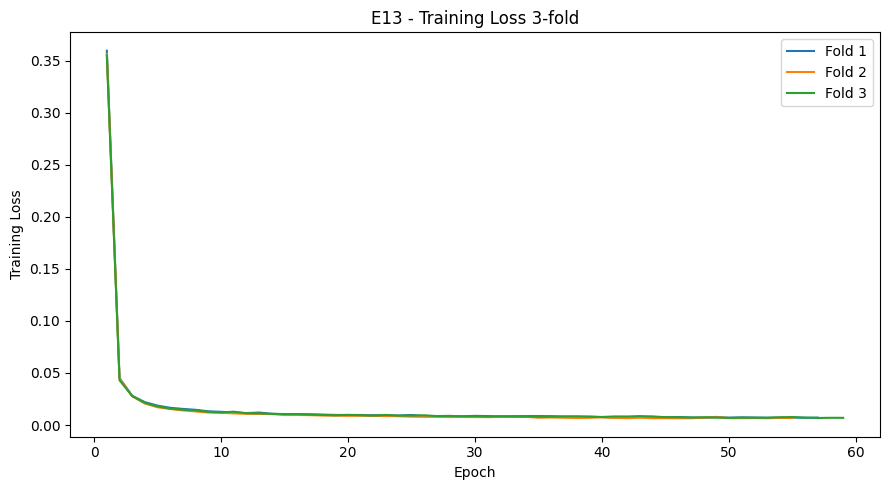

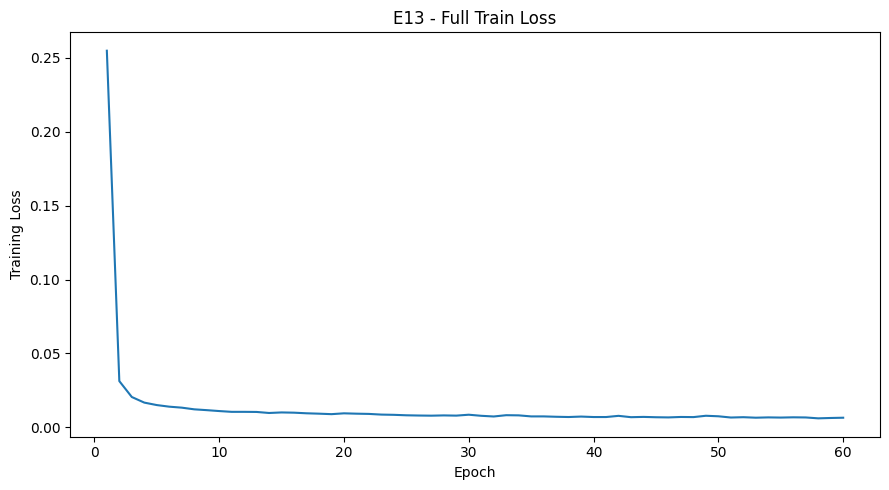

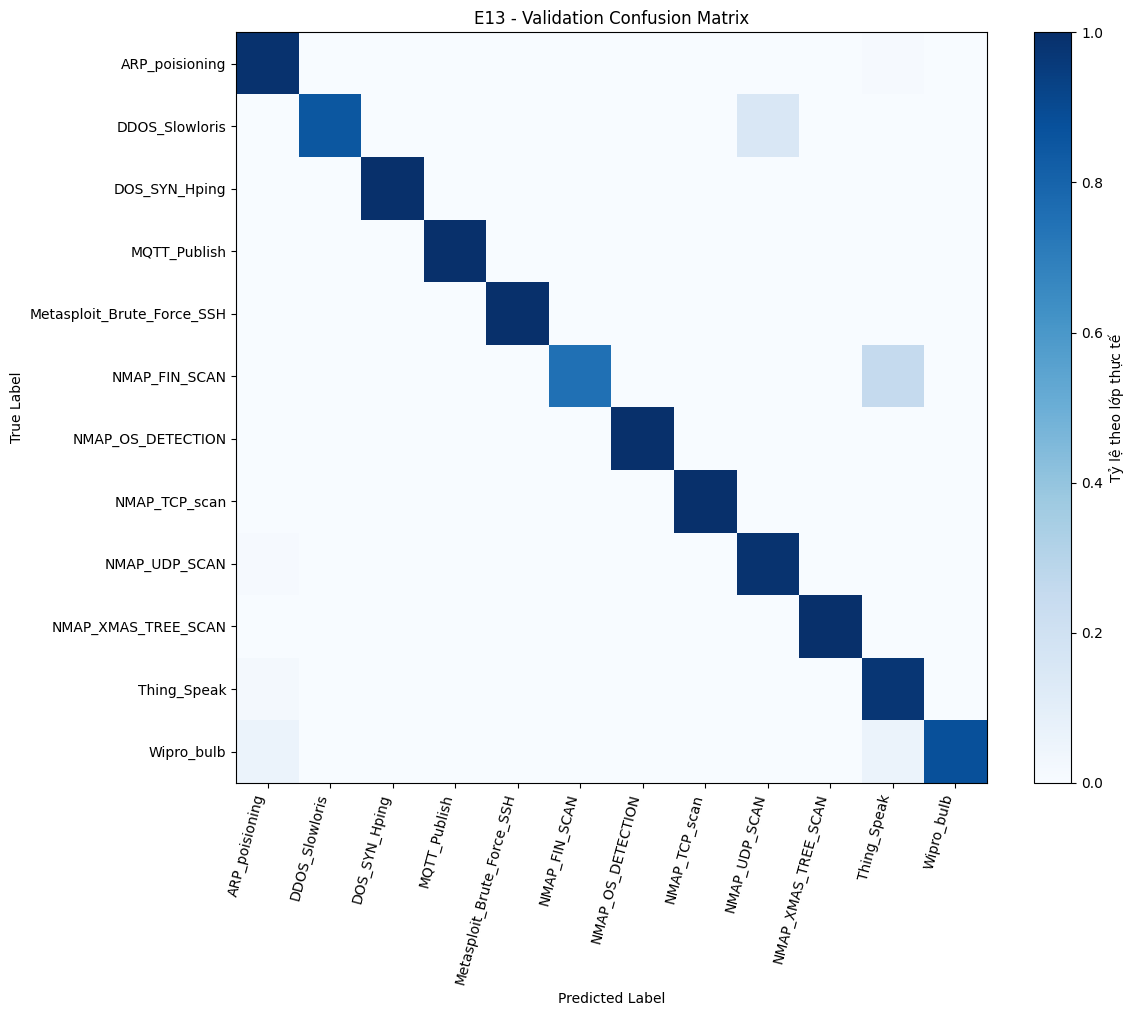

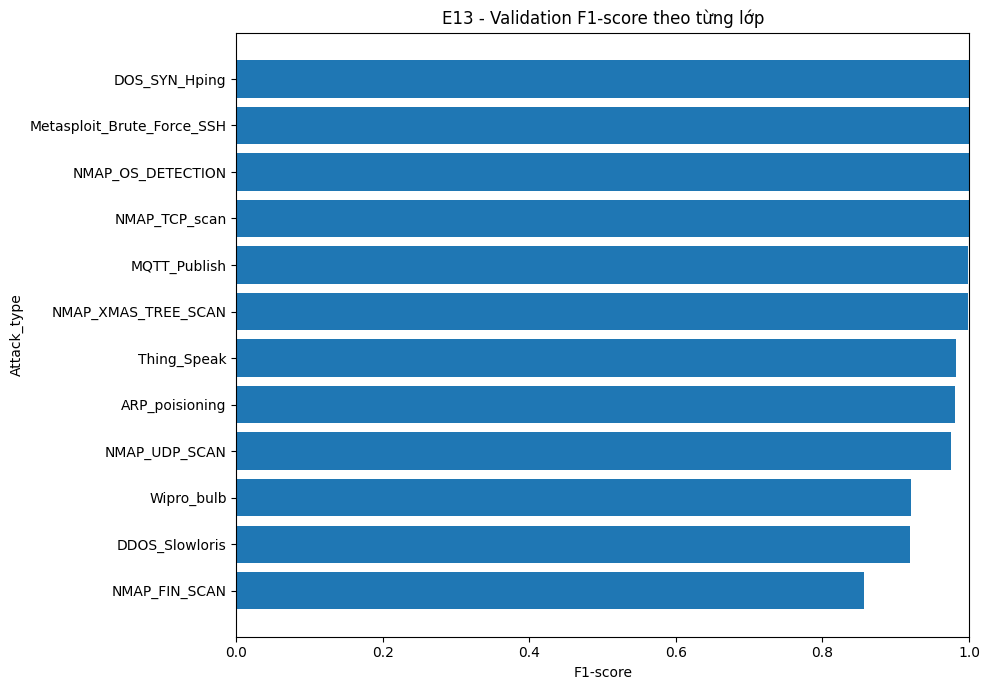

=== ĐÃ LƯU 4 HÌNH PNG ===
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\exps\E13_MLP_SignedLog2


In [5]:
# ========================================
# 5.1. TRAINING LOSS CỦA 3 FOLD
# ========================================

fig, ax = plt.subplots(figsize=(9, 5))

for fold, losses in loss_curves.items():

    ax.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"Fold {fold}"
    )

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("E13 - Training Loss 3-fold")

ax.legend()
fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E13_3fold_training_loss.png",
    dpi=160
)

plt.show()


# ========================================
# 5.2. TRAINING LOSS FULL TRAIN
# ========================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    range(1, len(final_mlp.loss_curve_) + 1),
    final_mlp.loss_curve_
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("E13 - Full Train Loss")

fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E13_full_train_loss.png",
    dpi=160
)

plt.show()


# ========================================
# 5.3. CONFUSION MATRIX VALIDATION
# ========================================

row_totals = cm.sum(
    axis=1,
    keepdims=True
)

cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    cm_normalized,
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))

ax.set_xticklabels(
    LABELS,
    rotation=75,
    ha="right"
)

ax.set_yticklabels(LABELS)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

ax.set_title(
    "E13 - Validation Confusion Matrix"
)

fig.colorbar(
    im,
    ax=ax,
    label="Tỷ lệ theo lớp thực tế"
)

fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E13_validation_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# ========================================
# 5.4. F1-SCORE THEO TỪNG LỚP
# ========================================

f1_plot = (
    validation_per_class
    .sort_values("f1")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    f1_plot["class"],
    f1_plot["f1"]
)

ax.set_xlim(0, 1)

ax.set_xlabel("F1-score")
ax.set_ylabel("Attack_type")

ax.set_title(
    "E13 - Validation F1-score theo từng lớp"
)

fig.tight_layout()

fig.savefig(
    RESULT_DIR / "E13_validation_f1_per_class.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("=== ĐÃ LƯU 4 HÌNH PNG ===")
print(RESULT_DIR)

### 5. Trực quan hóa kết quả E13

**Các biểu đồ:**
- Training Loss của 3 fold.
- Training Loss trên toàn bộ Train.
- Confusion Matrix trên Validation.
- F1-score theo từng lớp trên Validation.

**Ý nghĩa:**

Training Loss giúp quan sát quá trình
tối ưu của mạng MLP (128, 64).

Confusion Matrix giúp xác định các trường
hợp phân loại đúng và nhầm lẫn giữa các nhãn.

Biểu đồ F1-score giúp nhận diện những
lớp có khả năng dự đoán còn hạn chế.

# 6. Xuất file Excel và lưu cấu hình

In [6]:
from openpyxl import Workbook

from openpyxl.styles import (
    Font,
    Alignment,
    PatternFill,
    Border,
    Side
)

from openpyxl.utils import get_column_letter

# ========================================
# 1. TẠO WORKBOOK
# ========================================

excel_path = (
    RESULT_DIR / "E13_MLP_Exp_KetQua.xlsx"
)

wb = Workbook()
ws = wb.active

ws.title = "E13 MLP 128-64"
ws.sheet_view.showGridLines = False

# ========================================
# 2. TIÊU ĐỀ
# ========================================

ws.merge_cells("A1:Z1")

ws["A1"] = (
    "MÔ HÌNH: MLP - E13 SIGNED-LOG "
    "+ STANDARDSCALER + (128,64)"
)

# ========================================
# 3. NHÓM CỘT
# ========================================

groups = {
    "A2:D2": "Các lượt chạy 3 cross validation",
    "E2:I2": "Lượt 1",
    "J2:N2": "Lượt 2",
    "O2:S2": "Lượt 3",
    "T2:X2": "Valid",
    "Y2:Z2": "Nhận xét"
}

for cell_range, title in groups.items():

    ws.merge_cells(cell_range)

    first_cell = cell_range.split(":")[0]

    ws[first_cell] = title

# ========================================
# 4. TÊN CỘT
# ========================================

headers = (
    [
        "MÃ",
        "MÃ SO SÁNH",
        "Xử lý dữ liệu",
        "Thông số model"
    ]
    + METRICS * 4
    + [
        "Điểm yếu",
        "Đã khắc phục"
    ]
)

for col, header in enumerate(
    headers,
    start=1
):

    ws.cell(
        row=3,
        column=col,
        value=header
    )

# ========================================
# 5. THÔNG TIN E13
# ========================================

ws["A4"] = "E13"
ws["B4"] = "E12"

ws["C4"] = (
    "Giữ Signed-log trước StandardScaler "
    "trên nhánh numeric; "
    "OneHotEncoder cho proto và service."
)

ws["D4"] = (
    "MLP (128,64), ReLU, Adam; "
    "alpha=0.0001, "
    "learning_rate_init=0.001, "
    "batch_size=512, "
    "max_iter=60, "
    "n_iter_no_change=8, "
    "early_stopping=False, "
    "random_state=42"
)

# ========================================
# 6. KẾT QUẢ 3 FOLD
# ========================================

scores_by_fold = cv_results.set_index("fold")

for fold in [1, 2, 3]:

    first_col = 5 + (fold - 1) * 5

    for idx, metric in enumerate(METRICS):

        score = float(
            scores_by_fold.loc[fold, metric]
        )

        cell = ws.cell(
            row=4,
            column=first_col + idx,
            value=score
        )

        cell.number_format = "0.000000"

# ========================================
# 7. KẾT QUẢ VALIDATION
# ========================================

for idx, metric in enumerate(METRICS):

    score = float(valid_scores[metric])

    cell = ws.cell(
        row=4,
        column=20 + idx,
        value=score
    )

    cell.number_format = "0.000000"

# ========================================
# 8. NHẬN XÉT
# ========================================

ws["Y4"] = (
    "Chưa so sánh với E12; "
    "cần xem xét F1/Recall các lớp."
)

ws["Z4"] = (
    "Đã thử mạng MLP (128,64); "
    "chưa kết luận hiệu quả cải tiến."
)

# ========================================
# 9. ĐỊNH DẠNG EXCEL
# ========================================

ws["A1"].font = Font(
    name="Calibri",
    size=14,
    bold=True,
    color="16324F"
)

ws["A1"].alignment = Alignment(
    horizontal="center",
    vertical="center"
)

ws.row_dimensions[1].height = 32
ws.row_dimensions[2].height = 26
ws.row_dimensions[3].height = 38
ws.row_dimensions[4].height = 85

# Màu tiêu đề
for row_number, fill_color in [
    (2, "DCEAF7"),
    (3, "EAF1F8")
]:

    for row in ws.iter_rows(
        min_row=row_number,
        max_row=row_number,
        min_col=1,
        max_col=26
    ):

        for cell in row:

            cell.fill = PatternFill(
                "solid",
                fgColor=fill_color
            )

            cell.font = Font(
                name="Calibri",
                size=10,
                bold=True,
                color="17324D"
            )

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
                wrap_text=True
            )

# Độ rộng các cột
width_by_column = {
    "A": 20,
    "B": 17,
    "C": 41,
    "D": 56,
    "Y": 40,
    "Z": 42
}

for col, width in width_by_column.items():

    ws.column_dimensions[col].width = width

for col in range(5, 25):

    letter = get_column_letter(col)

    ws.column_dimensions[letter].width = 17

# Viền và căn chỉnh
thin = Side(
    style="thin",
    color="C5D1DD"
)

for row in ws.iter_rows(
    min_row=3,
    max_row=4,
    min_col=1,
    max_col=26
):

    for cell in row:

        cell.border = Border(
            left=thin,
            right=thin,
            top=thin,
            bottom=thin
        )

        if cell.row == 4:

            cell.alignment = Alignment(
                horizontal=(
                    "center"
                    if 5 <= cell.column <= 24
                    else "left"
                ),
                vertical="center",
                wrap_text=True
            )

ws.freeze_panes = "E4"

# ========================================
# 10. LƯU FILE EXCEL
# ========================================

wb.save(excel_path)

print("=== ĐÃ XUẤT EXCEL E13 ===")
print(excel_path)

# ========================================
# 11. LƯU CẤU HÌNH THỰC NGHIỆM
# ========================================

config = {
    "experiment": "E13",
    "compare_id": "E12",
    "model": "MLPClassifier",
    "data_source": "result/preprocessing/E13_MLP_SignedLog2_Processing/data",
    "preprocessing_notebook": "E13_MLP_SignedLog2_Processing.ipynb",
    "train_path": str(TRAIN_PATH),
    "validation_path": str(VALID_PATH),

    "numeric_transform": "Signed-log",
    "numeric_scaler": "StandardScaler",
    "categorical_encoder": "OneHotEncoder",

    "hidden_layer_sizes": [128, 64],
    "activation": "relu",
    "solver": "adam",

    "alpha": 0.0001,
    "learning_rate_init": 0.001,
    "batch_size": 512,

    "max_iter": 60,
    "n_iter_no_change": 8,
    "early_stopping": False,

    "random_state": RANDOM_STATE,
    "cv_folds": N_SPLITS,

    "train_samples": int(len(X)),
    "validation_samples": int(len(X_valid)),

    "classes": LABELS,
    "test_used": False,
    "comparison_completed": False
}

with open(
    RESULT_DIR / "E13_config.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        config,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Đã lưu cấu hình E13.")

=== ĐÃ XUẤT EXCEL E13 ===
D:\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\exps\E13_MLP_SignedLog2\E13_MLP_Exp_KetQua.xlsx
Đã lưu cấu hình E13.
